In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
train=pd.read_csv('customer_churn_dataset-training-master.csv')
test=pd.read_csv('customer_churn_dataset-testing-master.csv')

In [4]:
train.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [5]:
test.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


# EDA

In [6]:
test.shape

(64374, 12)

In [7]:
test.dtypes

CustomerID            int64
Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

In [8]:
test.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [9]:
train.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [10]:
train.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')

In [11]:
test.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')

In [12]:
train=train.drop(columns='CustomerID',axis=1)
test=test.drop(columns='CustomerID',axis=1)

In [13]:
train.columns

Index(['Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls',
       'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend',
       'Last Interaction', 'Churn'],
      dtype='object')

In [14]:
column_list=['Age','Tenure','Usage Frequency','Support Calls','Payment Delay','Total Spend','Last Interaction','Churn']

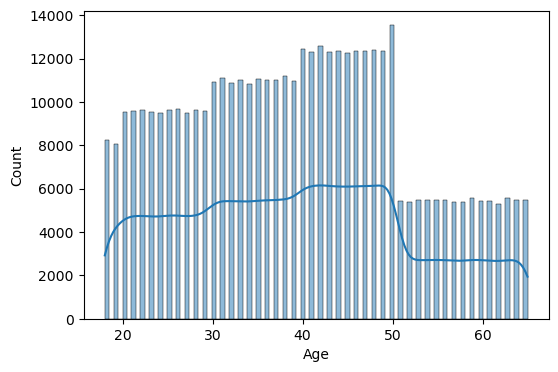

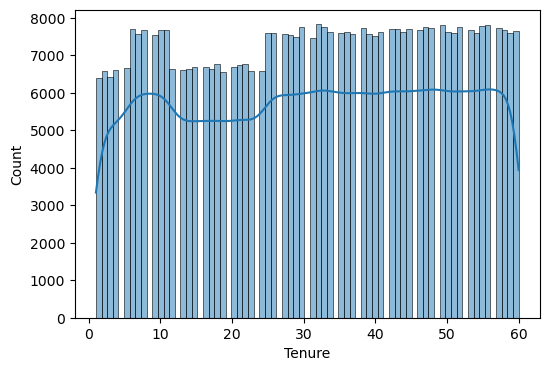

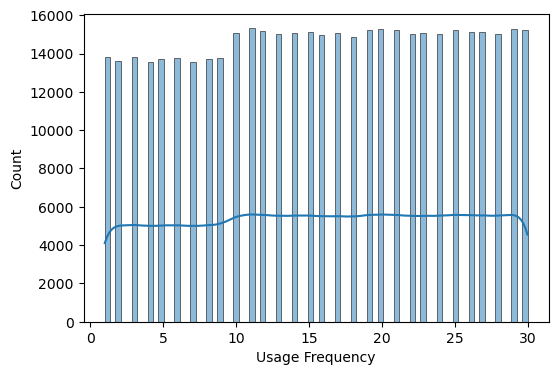

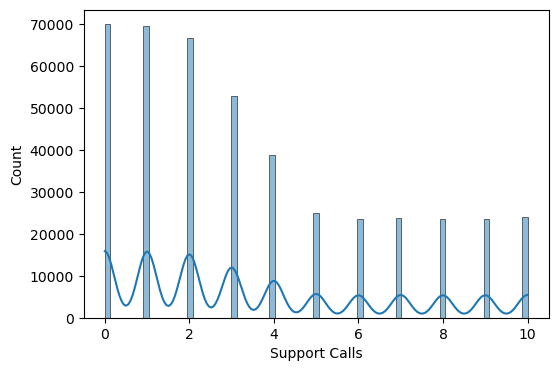

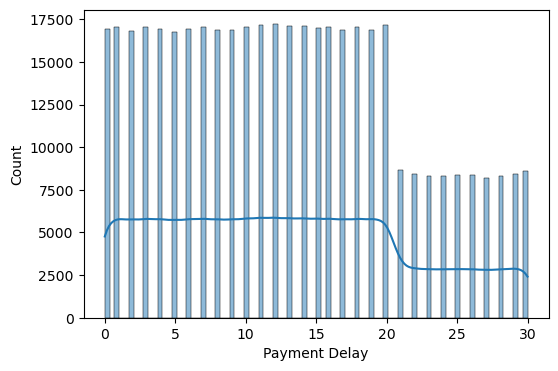

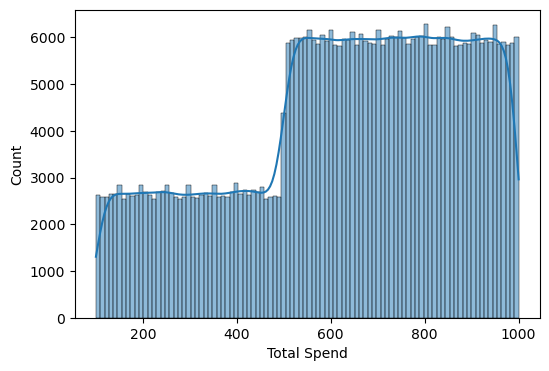

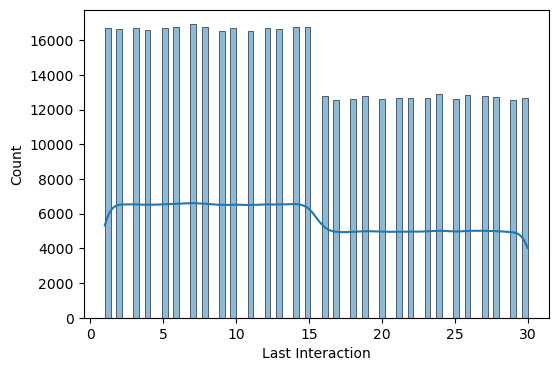

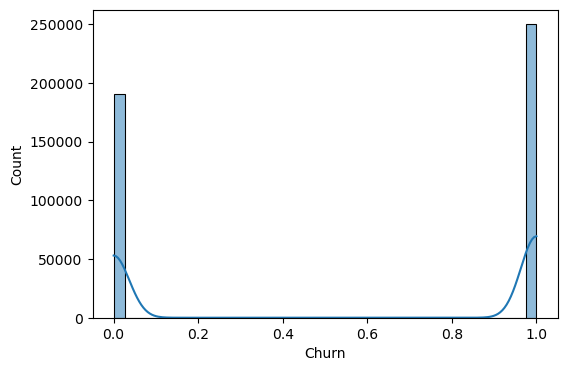

In [15]:
for col in column_list:
    plt.figure(figsize=(6,4))
    sns.histplot(train[col],kde=True)

<Axes: >

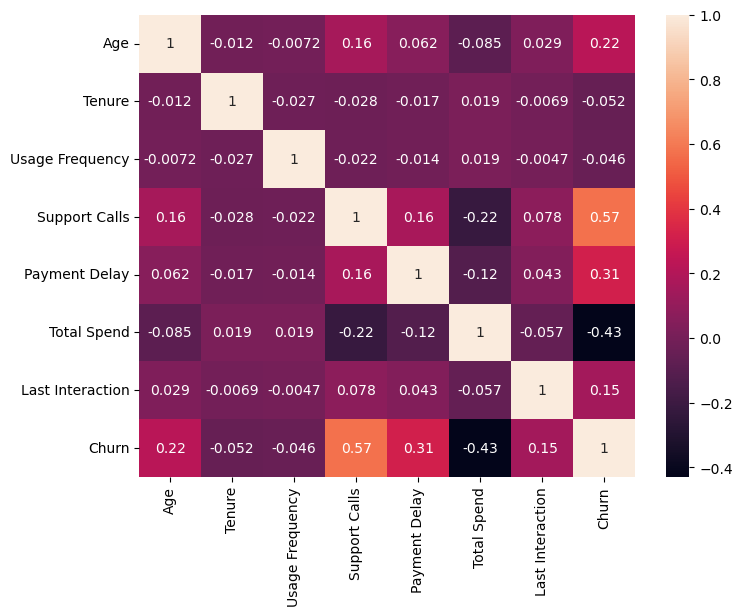

In [16]:
plt.figure(figsize=(8,6))
sns.heatmap(train.corr(numeric_only=True),annot=True)

# Data Cleaning

In [17]:
train.isnull().sum()

Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [18]:
# Fill numerical missing values
num_cols = train.select_dtypes(include="number").columns

for col in num_cols:
    train[col] = train[col].fillna(train[col].median())


In [19]:
# Categorical columns
cat_cols = train.select_dtypes(include="object").columns

for col in cat_cols:
    train[col] = train[col].fillna(train[col].mode()[0])

In [20]:
train.isnull().sum()

Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [21]:
test.isnull().sum()

Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [22]:
train.shape

(440833, 11)

In [23]:
test.shape

(64374, 11)

In [24]:
train=train.drop_duplicates()

In [25]:
test=test.drop_duplicates()

In [26]:
train.shape

(440833, 11)

In [27]:
test.shape

(64374, 11)

# Data Preprocessing

In [28]:
train.dtypes

Age                  float64
Gender                object
Tenure               float64
Usage Frequency      float64
Support Calls        float64
Payment Delay        float64
Subscription Type     object
Contract Length       object
Total Spend          float64
Last Interaction     float64
Churn                float64
dtype: object

In [29]:
test.dtypes

Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

In [30]:
train['Gender'].value_counts()

Gender
Male      250253
Female    190580
Name: count, dtype: int64

for train

In [31]:
train['Gender']=train['Gender'].map({'Male':0,'Female':1})

In [32]:
train=pd.get_dummies(train,columns=['Subscription Type','Contract Length'],drop_first=True)

In [33]:
train=train.astype(int)

In [34]:
train.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,30,1,39,14,5,18,932,17,1,0,1,0,0
1,65,1,49,1,10,8,557,6,1,0,0,1,0
2,55,1,14,4,6,18,185,3,1,0,0,0,1
3,58,0,38,21,7,7,396,29,1,0,1,1,0
4,23,0,32,20,5,8,617,20,1,0,0,1,0


For test

In [35]:
test.dtypes

Age                   int64
Gender               object
Tenure                int64
Usage Frequency       int64
Support Calls         int64
Payment Delay         int64
Subscription Type    object
Contract Length      object
Total Spend           int64
Last Interaction      int64
Churn                 int64
dtype: object

In [36]:
test['Gender']=test['Gender'].map({'Male':0,'Female':1})

In [37]:
test=pd.get_dummies(test,columns=['Subscription Type','Contract Length'],drop_first=True)

In [38]:
test=test.astype(int)

In [39]:
test.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,22,1,25,14,4,27,598,9,1,0,0,1,0
1,41,1,28,28,7,13,584,20,0,0,1,1,0
2,47,0,27,10,2,29,757,21,0,1,0,0,0
3,35,0,9,12,5,17,232,18,0,1,0,0,1
4,53,1,58,24,9,2,533,18,0,0,1,0,0


In [40]:
x_train=train.drop(columns='Churn',axis=1)
y_train=train['Churn']

In [41]:
x_test=test.drop(columns='Churn',axis=1)
y_test=test['Churn']

# Feature Scaling

In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)

x_test_scaled = scaler.transform(x_test)

In [43]:
print(x_train_scaled.shape)
print(x_test_scaled.shape)

(440833, 12)
(64374, 12)


# Apply Models

In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,f1_score,confusion_matrix

In [45]:
# models={
#     'lg':LogisticRegression(),
#     'dt':DecisionTreeClassifier(),
#     'svm':SVC(),
#     'gb':GaussianNB(),
#     'knn':KNeighborsClassifier(),
#     'rf':RandomForestClassifier()
# }

models = {
    'Logistic Regression': LogisticRegression(max_iter=500),
    'Decision Tree': DecisionTreeClassifier(max_depth=15),
    'GaussianNB': GaussianNB(),
    'Random Forest': RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        n_jobs=-1,
        random_state=42
    )
}

In [46]:
results=[]

In [47]:
for name,model in models.items():
    model.fit(x_train_scaled,y_train)
    y_pred=model.predict(x_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)
    results.append({
        'Model':name,
        'accuracy':round(acc,4),
        'F1_score':round(f1,4)
    })


In [48]:
results

[{'Model': 'Logistic Regression', 'accuracy': 0.5713, 'F1_score': 0.6864},
 {'Model': 'Decision Tree', 'accuracy': 0.5034, 'F1_score': 0.6558},
 {'Model': 'GaussianNB', 'accuracy': 0.6109, 'F1_score': 0.6361},
 {'Model': 'Random Forest', 'accuracy': 0.5044, 'F1_score': 0.6562}]

# XGBoost

In [49]:
from xgboost import XGBClassifier

In [51]:
xg=XGBClassifier(n_estimator=100,max_depth=3,learning_rate=0.1,random_state=42)
xg.fit(x_train_scaled,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,None


In [52]:
xg_pred=xg.predict(x_test_scaled)

In [53]:
print(accuracy_score(y_test,xg_pred))

0.5089943144747879


In [58]:
import joblib

gb = models['GaussianNB']          # dictionary se trained model nikalein
joblib.dump(gb, 'gb.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(x_train.columns.tolist(), 'columns.pkl')

['columns.pkl']